In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from pathlib import Path

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


In [5]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
from pathlib import Path

carpeta_datos = Path("datos")
carpeta_datos.mkdir(parents=True, exist_ok=True)

print("Carpeta preparada:", carpeta_datos.resolve())


Carpeta preparada: C:\Users\Kath\OneDrive\Escritorio\analitica_de_datos\Carga-y-Creaci-n-de-Dataset\Actividad_3\datos


In [8]:
URL = "https://archive-api.open-meteo.com/v1/archive"

def descargar_clima(ciudad, latitud, longitud, zona_horaria, archivo):

    parametros = {
        "latitude": latitud,
        "longitude": longitud,
        "start_date": "2025-01-01",
        "end_date": "2025-12-31",
        "daily": "temperature_2m_max,precipitation_sum",
        "temperature_unit": "celsius",
        "precipitation_unit": "mm",
        "timezone": zona_horaria,
        "models": "era5"
    }

    respuesta = requests.get(URL, params=parametros, timeout=60)
    respuesta.raise_for_status()

    datos = respuesta.json()
    tabla = pd.DataFrame(datos["daily"])

    tabla = tabla.rename(columns={
        "time": "fecha",
        "temperature_2m_max": "temperatura_maxima",
        "precipitation_sum": "precipitacion"
    })

    tabla["fecha"] = pd.to_datetime(tabla["fecha"])

    ruta = carpeta_datos / archivo
    tabla.to_csv(ruta, index=False)

    print(f"{ciudad}: {len(tabla)} registros descargados.")
    print(f"Archivo guardado: {ruta}")

    return tabla


In [9]:
medellin = descargar_clima(
    "Medellín", 6.2442, -75.5812,
    "America/Bogota", "medellin.csv"
)

madrid = descargar_clima(
    "Madrid", 40.4168, -3.7038,
    "Europe/Madrid", "madrid.csv"
)

Medellín: 365 registros descargados.
Archivo guardado: datos\medellin.csv
Madrid: 365 registros descargados.
Archivo guardado: datos\madrid.csv


In [10]:
print("DATOS DE MEDELLÍN")
display(medellin.head())

print("\nDATOS DE MADRID")
display(madrid.head())

print("\nDIMENSIONES")
print("Medellín:", medellin.shape)
print("Madrid:", madrid.shape)

print("\nARCHIVOS GUARDADOS")
print(list(carpeta_datos.iterdir()))


DATOS DE MEDELLÍN


,fecha,temperatura_maxima,precipitacion
0,2025-01-01,23.6,2.1
1,2025-01-02,25.0,11.7
2,2025-01-03,24.1,18.4
3,2025-01-04,25.0,11.6
4,2025-01-05,25.3,12.3



DATOS DE MADRID


,fecha,temperatura_maxima,precipitacion
0,2025-01-01,9.5,0.0
1,2025-01-02,9.5,0.0
2,2025-01-03,9.0,0.0
3,2025-01-04,7.8,0.1
4,2025-01-05,9.8,5.4



DIMENSIONES
Medellín: (365, 3)
Madrid: (365, 3)

ARCHIVOS GUARDADOS
[WindowsPath('datos/madrid.csv'), WindowsPath('datos/medellin.csv')]


In [11]:
# Revisar información general de Medellín
print("INFORMACIÓN DE MEDELLÍN")
medellin.info()

print("\nINFORMACIÓN DE MADRID")
madrid.info()

# Revisar valores faltantes
print("\nVALORES FALTANTES")
print("Medellín:")
print(medellin.isnull().sum())

print("\nMadrid:")
print(madrid.isnull().sum())

# Revisar fechas duplicadas
print("\nFECHAS DUPLICADAS")
print("Medellín:", medellin["fecha"].duplicated().sum())
print("Madrid:", madrid["fecha"].duplicated().sum())

# Revisar fechas iniciales y finales
print("\nPERÍODO ANALIZADO")
print("Medellín:", medellin["fecha"].min(), "a", medellin["fecha"].max())
print("Madrid:", madrid["fecha"].min(), "a", madrid["fecha"].max())


INFORMACIÓN DE MEDELLÍN
<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   fecha               365 non-null    datetime64[us]
 1   temperatura_maxima  365 non-null    float64       
 2   precipitacion       365 non-null    float64       
dtypes: datetime64[us](1), float64(2)
memory usage: 8.7 KB

INFORMACIÓN DE MADRID
<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   fecha               365 non-null    datetime64[us]
 1   temperatura_maxima  365 non-null    float64       
 2   precipitacion       365 non-null    float64       
dtypes: datetime64[us](1), float64(2)
memory usage: 8.7 KB

VALORES FALTANTES
Medellín:
fecha                 0
temperatura_maxima    0
precipitacio

In [12]:
print("RESUMEN DE CALIDAD DE LOS DATOS")

for ciudad, tabla in [("Medellín", medellin), ("Madrid", madrid)]:

    print(f"\n{ciudad}")
    print("Valores faltantes:")
    print(tabla.isnull().sum().to_dict())

    print("Fechas duplicadas:", tabla["fecha"].duplicated().sum())

    print("Temperaturas negativas:",
          (tabla["temperatura_maxima"] < 0).sum())

    print("Precipitaciones negativas:",
          (tabla["precipitacion"] < 0).sum())

# Comparar fechas entre las dos ciudades
fechas_comunes = pd.Index(medellin["fecha"]).intersection(
    pd.Index(madrid["fecha"])
)

print("\nCOMPARACIÓN")
print("Fechas comunes:", len(fechas_comunes))

RESUMEN DE CALIDAD DE LOS DATOS

Medellín
Valores faltantes:
{'fecha': 0, 'temperatura_maxima': 0, 'precipitacion': 0}
Fechas duplicadas: 0
Temperaturas negativas: 0
Precipitaciones negativas: 0

Madrid
Valores faltantes:
{'fecha': 0, 'temperatura_maxima': 0, 'precipitacion': 0}
Fechas duplicadas: 0
Temperaturas negativas: 0
Precipitaciones negativas: 0

COMPARACIÓN
Fechas comunes: 365


In [13]:
# Convertir las columnas numéricas en arreglos NumPy

temp_medellin = medellin["temperatura_maxima"].to_numpy()
temp_madrid = madrid["temperatura_maxima"].to_numpy()

prec_medellin = medellin["precipitacion"].to_numpy()
prec_madrid = madrid["precipitacion"].to_numpy()

fechas = medellin["fecha"].to_numpy()

# Mostrar dimensiones de los arreglos

print("DIMENSIONES DE LOS ARREGLOS")

print("Temperaturas Medellín:", temp_medellin.shape)
print("Temperaturas Madrid:", temp_madrid.shape)

print("Precipitaciones Medellín:", prec_medellin.shape)
print("Precipitaciones Madrid:", prec_madrid.shape)

print("Fechas:", fechas.shape)

# Mostrar los primeros cinco registros

print("\nPRIMEROS CINCO REGISTROS")

print("Temperaturas Medellín:", temp_medellin[:5])
print("Temperaturas Madrid:", temp_madrid[:5])

DIMENSIONES DE LOS ARREGLOS
Temperaturas Medellín: (365,)
Temperaturas Madrid: (365,)
Precipitaciones Medellín: (365,)
Precipitaciones Madrid: (365,)
Fechas: (365,)

PRIMEROS CINCO REGISTROS
Temperaturas Medellín: [23.6 25.  24.1 25.  25.3]
Temperaturas Madrid: [9.5 9.5 9.  7.8 9.8]


In [14]:
# Estadísticas de temperatura máxima

print("ESTADÍSTICAS DE TEMPERATURA")

print("\nMEDELLÍN")
print("Promedio:", round(np.mean(temp_medellin), 2), "°C")
print("Mínima:", round(np.min(temp_medellin), 2), "°C")
print("Máxima:", round(np.max(temp_medellin), 2), "°C")

print("\nMADRID")
print("Promedio:", round(np.mean(temp_madrid), 2), "°C")
print("Mínima:", round(np.min(temp_madrid), 2), "°C")
print("Máxima:", round(np.max(temp_madrid), 2), "°C")


# Estadísticas de precipitación

print("\nESTADÍSTICAS DE PRECIPITACIÓN")

print("\nMEDELLÍN")
print("Precipitación total:", round(np.sum(prec_medellin), 2), "mm")
print("Promedio diario:", round(np.mean(prec_medellin), 2), "mm")

print("\nMADRID")
print("Precipitación total:", round(np.sum(prec_madrid), 2), "mm")
print("Promedio diario:", round(np.mean(prec_madrid), 2), "mm")

ESTADÍSTICAS DE TEMPERATURA

MEDELLÍN
Promedio: 25.17 °C
Mínima: 21.4 °C
Máxima: 30.2 °C

MADRID
Promedio: 21.3 °C
Mínima: 5.0 °C
Máxima: 39.2 °C

ESTADÍSTICAS DE PRECIPITACIÓN

MEDELLÍN
Precipitación total: 3345.2 mm
Promedio diario: 9.16 mm

MADRID
Precipitación total: 628.5 mm
Promedio diario: 1.72 mm


In [15]:
# Definir condiciones

umbral_lluvia = 1.0
umbral_temperatura = 25.0

# Crear máscaras booleanas

lluvia_medellin = prec_medellin > umbral_lluvia
lluvia_madrid = prec_madrid > umbral_lluvia

calor_medellin = temp_medellin > umbral_temperatura
calor_madrid = temp_madrid > umbral_temperatura

# Contar los días que cumplen las condiciones

print("DÍAS LLUVIOSOS (más de 1 mm)")

print("Medellín:", np.sum(lluvia_medellin))
print("Madrid:", np.sum(lluvia_madrid))

print("\nDÍAS CON TEMPERATURA SUPERIOR A 25 °C")

print("Medellín:", np.sum(calor_medellin))
print("Madrid:", np.sum(calor_madrid))

# Mostrar algunos días que cumplen las condiciones

print("\nPRIMEROS DÍAS LLUVIOSOS EN MEDELLÍN")
print(fechas[lluvia_medellin][:10])

print("\nPRIMEROS DÍAS CALUROSOS EN MADRID")
print(fechas[calor_madrid][:10])

DÍAS LLUVIOSOS (más de 1 mm)
Medellín: 325
Madrid: 84

DÍAS CON TEMPERATURA SUPERIOR A 25 °C
Medellín: 189
Madrid: 132

PRIMEROS DÍAS LLUVIOSOS EN MEDELLÍN
['2025-01-01T00:00:00.000000' '2025-01-02T00:00:00.000000'
 '2025-01-03T00:00:00.000000' '2025-01-04T00:00:00.000000'
 '2025-01-05T00:00:00.000000' '2025-01-06T00:00:00.000000'
 '2025-01-07T00:00:00.000000' '2025-01-08T00:00:00.000000'
 '2025-01-09T00:00:00.000000' '2025-01-10T00:00:00.000000']

PRIMEROS DÍAS CALUROSOS EN MADRID
['2025-04-24T00:00:00.000000' '2025-04-25T00:00:00.000000'
 '2025-05-18T00:00:00.000000' '2025-05-21T00:00:00.000000'
 '2025-05-24T00:00:00.000000' '2025-05-25T00:00:00.000000'
 '2025-05-26T00:00:00.000000' '2025-05-27T00:00:00.000000'
 '2025-05-28T00:00:00.000000' '2025-05-29T00:00:00.000000']


In [16]:
# Broadcasting: restar los arreglos diarios de temperatura

diferencia_temperatura = temp_medellin - temp_madrid

print("COMPARACIÓN DIARIA DE TEMPERATURAS")
print("Diferencia promedio:", round(np.mean(diferencia_temperatura), 2), "°C")
print("Mayor diferencia:", round(np.max(diferencia_temperatura), 2), "°C")
print("Menor diferencia:", round(np.min(diferencia_temperatura), 2), "°C")

print("\nPrimeras cinco diferencias:")
print(diferencia_temperatura[:5])

COMPARACIÓN DIARIA DE TEMPERATURAS
Diferencia promedio: 3.87 °C
Mayor diferencia: 21.3 °C
Menor diferencia: -16.7 °C

Primeras cinco diferencias:
[14.1 15.5 15.1 17.2 15.5]


In [17]:
# Crear una copia de los datos
medellin_mensual = medellin.copy()
madrid_mensual = madrid.copy()

# Extraer el número del mes
medellin_mensual["mes"] = medellin_mensual["fecha"].dt.month
madrid_mensual["mes"] = madrid_mensual["fecha"].dt.month

# Calcular estadísticas mensuales
resumen_medellin = medellin_mensual.groupby("mes").agg(
    temperatura_promedio=("temperatura_maxima", "mean"),
    precipitacion_total=("precipitacion", "sum")
)

resumen_madrid = madrid_mensual.groupby("mes").agg(
    temperatura_promedio=("temperatura_maxima", "mean"),
    precipitacion_total=("precipitacion", "sum")
)

# Mostrar resultados
print("RESUMEN MENSUAL DE MEDELLÍN")
display(resumen_medellin.round(2))

print("RESUMEN MENSUAL DE MADRID")
display(resumen_madrid.round(2))

RESUMEN MENSUAL DE MEDELLÍN


,temperatura_promedio,precipitacion_total
mes,,
1,26.34,104.1
2,25.07,325.4
3,25.86,275.9
4,24.97,488.0
5,25.03,342.4
6,25.03,280.3
7,26.63,138.4
8,25.45,235.3
9,25.42,268.5


RESUMEN MENSUAL DE MADRID


,temperatura_promedio,precipitacion_total
mes,,
1,11.27,49.7
2,14.28,17.7
3,12.76,235.5
4,18.65,80.8
5,22.76,61.4
6,32.82,17.2
7,33.25,1.0
8,33.93,3.5
9,27.73,3.2


In [18]:
# Unir los resultados mensuales de ambas ciudades

comparacion_mensual = pd.DataFrame({
    "Temperatura Medellín (°C)": resumen_medellin["temperatura_promedio"],
    "Temperatura Madrid (°C)": resumen_madrid["temperatura_promedio"],
    "Precipitación Medellín (mm)": resumen_medellin["precipitacion_total"],
    "Precipitación Madrid (mm)": resumen_madrid["precipitacion_total"]
})

print("COMPARACIÓN CLIMÁTICA MENSUAL: MEDELLÍN VS MADRID")

display(comparacion_mensual.round(2))

COMPARACIÓN CLIMÁTICA MENSUAL: MEDELLÍN VS MADRID


,Temperatura Medellín (°C),Temperatura Madrid (°C),Precipitación Medellín (mm),Precipitación Madrid (mm)
mes,,,,
1,26.34,11.27,104.1,49.7
2,25.07,14.28,325.4,17.7
3,25.86,12.76,275.9,235.5
4,24.97,18.65,488.0,80.8
5,25.03,22.76,342.4,61.4
6,25.03,32.82,280.3,17.2
7,26.63,33.25,138.4,1.0
8,25.45,33.93,235.3,3.5
9,25.42,27.73,268.5,3.2


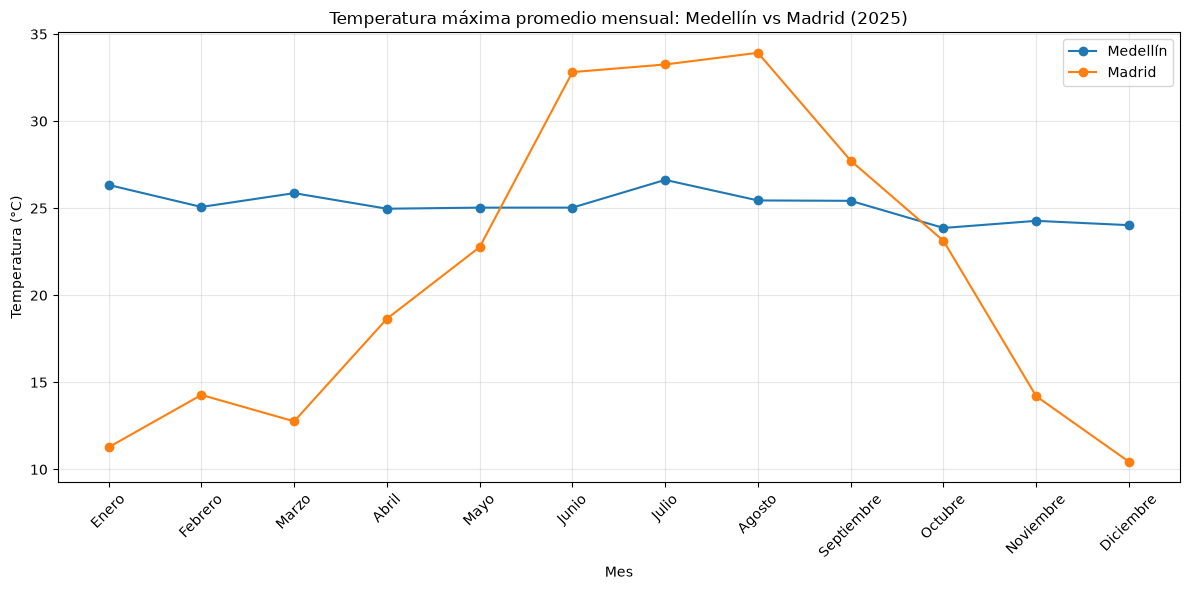

In [19]:
meses = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

plt.figure(figsize=(12, 6))

plt.plot(
    meses,
    resumen_medellin["temperatura_promedio"],
    marker="o",
    label="Medellín"
)

plt.plot(
    meses,
    resumen_madrid["temperatura_promedio"],
    marker="o",
    label="Madrid"
)

plt.title("Temperatura máxima promedio mensual: Medellín vs Madrid (2025)")
plt.xlabel("Mes")
plt.ylabel("Temperatura (°C)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#1. Interpretación de la primera gráfica
#Estos son los hallazgos que podemos documentar:
#- Medellín: mantiene temperaturas bastante estables durante el año, entre 23,86 °C y 26,63 °C.
#- Madrid: presenta una variación estacional mucho más marcada. Sus temperaturas aumentan desde 10,44 °C en diciembre hasta 33,93 °C en agosto.
#- Comparación: entre junio y septiembre, Madrid registra temperaturas promedio superiores a Medellín; en los meses más fríos ocurre lo contrario.

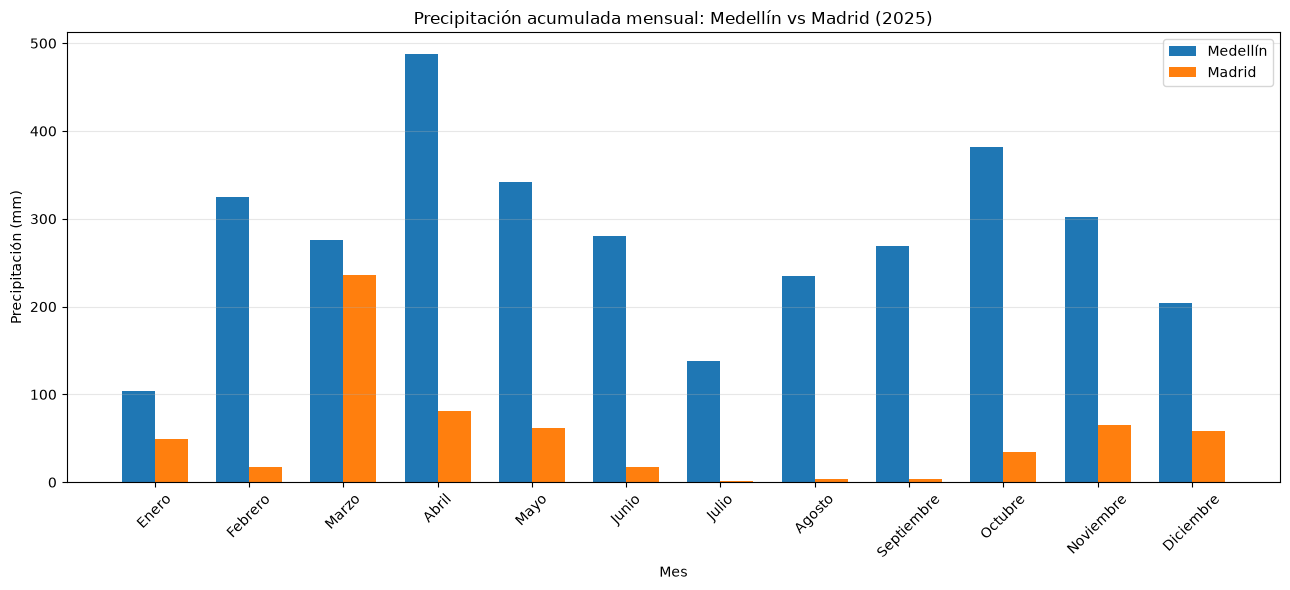

In [20]:
# Gráfica de precipitación mensual

meses = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

posiciones = np.arange(len(meses))
ancho = 0.35

plt.figure(figsize=(13, 6))

plt.bar(
    posiciones - ancho / 2,
    resumen_medellin["precipitacion_total"],
    ancho,
    label="Medellín"
)

plt.bar(
    posiciones + ancho / 2,
    resumen_madrid["precipitacion_total"],
    ancho,
    label="Madrid"
)

plt.title("Precipitación acumulada mensual: Medellín vs Madrid (2025)")
plt.xlabel("Mes")
plt.ylabel("Precipitación (mm)")
plt.xticks(posiciones, meses, rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
#1. Interpretación de la segunda gráfica
#Podemos documentar estos resultados:
#- Medellín: abril fue el mes más lluvioso, con 488 mm; enero fue el menos lluvioso, con 104,1 mm.
#- Madrid: marzo presentó la mayor precipitación, con 235,5 mm.
#- Diferencia estacional: Madrid tuvo precipitaciones muy bajas durante julio (1 mm), agosto (3,5 mm) y septiembre (3,2 mm).
#- Comparación: Medellín acumuló más precipitación que Madrid en todos los meses de 2025.

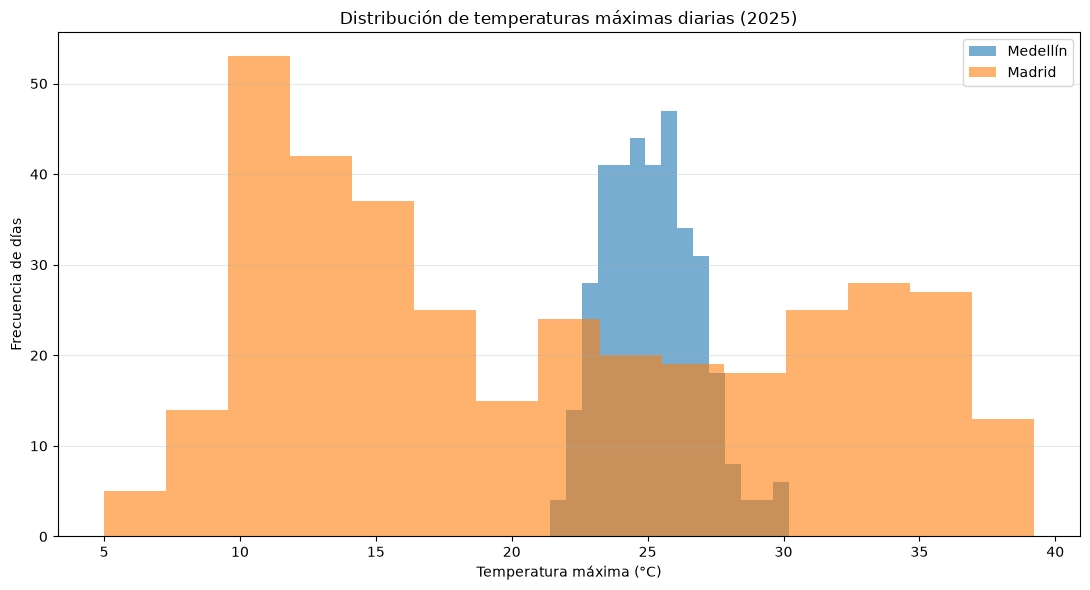

In [22]:
# Distribución de temperaturas máximas diarias

plt.figure(figsize=(11, 6))

plt.hist(
    temp_medellin,
    bins=15,
    alpha=0.6,
    label="Medellín"
)

plt.hist(
    temp_madrid,
    bins=15,
    alpha=0.6,
    label="Madrid"
)

plt.title("Distribución de temperaturas máximas diarias (2025)")
plt.xlabel("Temperatura máxima (°C)")
plt.ylabel("Frecuencia de días")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#1. Interpretación de la tercera gráfica
#Puedes incluir esta explicación debajo de la gráfica en tu notebook:
#- Medellín: las temperaturas máximas se concentran principalmente entre 23 °C y 27 °C, lo que refleja una distribución relativamente estable.
#- Madrid: presenta una distribución más amplia, con temperaturas desde aproximadamente 5 °C hasta 39 °C.
#- Comparación: Medellín tiene menor variabilidad térmica, mientras que Madrid presenta cambios más pronunciados entre las estaciones del año.

In [23]:
# Calcular la desviación estándar de las temperaturas

desviacion_medellin = np.std(temp_medellin)
desviacion_madrid = np.std(temp_madrid)

print("VARIABILIDAD DE LAS TEMPERATURAS")
print("Medellín:", round(desviacion_medellin, 2), "°C")
print("Madrid:", round(desviacion_madrid, 2), "°C")

if desviacion_medellin < desviacion_madrid:
    print("\nMedellín presenta menor variabilidad térmica.")
else:
    print("\nMadrid presenta menor variabilidad térmica.")

VARIABILIDAD DE LAS TEMPERATURAS
Medellín: 1.71 °C
Madrid: 9.27 °C

Medellín presenta menor variabilidad térmica.


## Hallazgos de la comparación climática

Después de analizar los datos de Medellín y Madrid durante el año 2025, encontramos algunas diferencias importantes en el comportamiento de su clima.

**Hallazgo 1. Diferencias en las precipitaciones**

Una de las diferencias más notables fue la cantidad de lluvia registrada en cada ciudad. Medellín acumuló 3.345,2 mm de precipitación durante el año, mientras que Madrid registró 628,5 mm. Esto muestra que Medellín tuvo una cantidad de lluvia mucho mayor durante el período analizado.

**Hallazgo 2. Comportamiento de las temperaturas**

En cuanto a las temperaturas, Medellín presentó un promedio de temperatura máxima diaria de 25,17 °C, mientras que Madrid tuvo un promedio de 21,30 °C. Sin embargo, Madrid alcanzó una temperatura máxima de 39,2 °C, mientras que Medellín llegó a 30,2 °C.

**Hallazgo 3. Cambios de temperatura durante el año**

Al observar las gráficas mensuales, notamos que Medellín mantuvo temperaturas bastante similares durante todo el año. En cambio, Madrid presentó cambios más marcados: tuvo temperaturas bajas al comienzo y al final del año, y temperaturas mucho más altas durante los meses de verano.

**Hallazgo 4. Cantidad de días lluviosos**

También comparamos los días en los que la precipitación fue superior a 1 mm. Medellín registró 325 días bajo esta condición, mientras que Madrid tuvo 84. Esto permite observar otra diferencia importante entre los patrones de lluvia de ambas ciudades.

## Limitaciones del análisis

Durante el desarrollo de esta actividad tuvimos en cuenta algunos aspectos que pueden influir en los resultados:

- El análisis se realizó únicamente con datos del año 2025, por lo que no podemos asegurar que el comportamiento sea igual en otros años.
- La información se obtuvo de Open-Meteo mediante el modelo ERA5. Por esta razón, los datos corresponden a estimaciones de reanálisis y no a mediciones directas realizadas por una estación meteorológica específica.
- Para cada ciudad se utilizaron unas coordenadas de referencia. Esto significa que los resultados no representan necesariamente todas las condiciones climáticas de Medellín y Madrid, ya que dentro de una misma ciudad pueden existir variaciones.
- El trabajo se concentró en dos variables: temperatura máxima diaria y precipitación acumulada diaria. No se tuvieron en cuenta otros factores como la humedad, el viento o la temperatura mínima.
- Finalmente, los resultados nos permiten comparar el comportamiento climático de las dos ciudades, pero no explicar por sí solos las causas de las diferencias encontradas.

tambien conviene aclarar que la temperatura utilizada es la temperatura máxima diaria, no la temperatura promedio del día. Las tablas mensuales muestran el promedio de esas temperaturas máximas diarias.

## Conclusiones

A través de esta actividad pudimos comparar el comportamiento climático de Medellín, Colombia, y Madrid, España, durante el año 2025. Para realizar el análisis utilizamos Python y algunas de sus principales librerías, como Pandas, NumPy y Matplotlib, que nos permitieron organizar los datos, realizar cálculos y representar los resultados mediante gráficas.

Uno de los resultados que más llamó nuestra atención fue la diferencia en las precipitaciones. Medellín acumuló 3.345,2 mm durante el año, mientras que Madrid registró 628,5 mm. También encontramos que Medellín tuvo 325 días con precipitaciones superiores a 1 mm, frente a los 84 días registrados en Madrid.

En cuanto a la temperatura, Medellín mantuvo valores más estables durante el año, con un promedio de 25,17 °C y una desviación estándar de 1,71 °C. Por otro lado, Madrid presentó una mayor variación, con un promedio de 21,30 °C y una desviación estándar de 9,27 °C. Esto también se pudo observar en las gráficas, donde Madrid mostró cambios más marcados entre los meses fríos y cálidos.

En general, esta actividad nos permitió poner en práctica los conocimientos adquiridos sobre el manejo y análisis de datos. Aprendimos a obtener información desde una API, trabajar con archivos CSV, revisar la calidad de los datos, utilizar arreglos y operaciones de NumPy, aplicar condiciones mediante máscaras booleanas y crear visualizaciones para interpretar los resultados.

Finalmente, consideramos que el ejercicio fue útil para comprender cómo las herramientas de programación pueden ayudarnos a analizar información real y encontrar diferencias que no serían tan fáciles de identificar observando únicamente los datos en una tabla.

## Fuente de datos y metodología

Para desarrollar esta actividad utilizamos la información histórica disponible en Open-Meteo, a través de su API de datos meteorológicos.

**Fuente de información:** Open-Meteo – Historical Weather API.

**Enlace:** https://open-meteo.com/en/docs/historical-weather-api

**Modelo utilizado:** ERA5.

**Ciudades seleccionadas:**
- Medellín, Colombia.
- Madrid, España.

**Período de análisis:** del 1 de enero al 31 de diciembre de 2025.

**Frecuencia:** diaria.

**Variables utilizadas:**
- Temperatura máxima diaria, expresada en grados Celsius (°C).
- Precipitación acumulada diaria, expresada en milímetros (mm).

**Herramientas utilizadas:** Python, Pandas, NumPy, Matplotlib y Requests.

La información se obtuvo mediante solicitudes a la API de Open-Meteo. Posteriormente, los datos de cada ciudad se guardaron en archivos CSV independientes para poder trabajar con ellos desde Jupyter Notebook.

Después realizamos una revisión de los registros, comprobamos que no hubiera valores faltantes ni fechas duplicadas y verificamos que ambas ciudades tuvieran las mismas fechas de análisis. Finalmente, utilizamos NumPy para realizar los cálculos y Matplotlib para construir las gráficas que facilitaron la comparación de los resultados.